# 2. Logistic Regression: Identifying a Chemical

**Question.** After use, residue of two acids is hard to tell apart. Can temperature and the presence of lumps identify whether the residue is hydrochloric acid (1) or sulfuric acid (0), and which classification threshold should be used?

**Data.** 120 samples (`data/acid_classification.csv`), synthetic course data. The model is evaluated on the same data it is fitted on, as the assignment required. With only 120 rows, the threshold results below are optimistic and would need a hold-out set or cross-validation in practice.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore")
DATA = Path("../data"); FIG = Path("../images"); FIG.mkdir(exist_ok=True)
BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#c9c8c2", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#ecebe7", "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
})
from sklearn.metrics import roc_auc_score, roc_curve

df = pd.read_csv(DATA / "acid_classification.csv")
print(f"{len(df)} samples, {df.hydrochloric_acid.mean():.1%} hydrochloric")
pd.crosstab(df.lumps, df.hydrochloric_acid, margins=True)

120 samples, 34.2% hydrochloric


hydrochloric_acid,0,1,All
lumps,,,
0,32,32,64
1,47,9,56
All,79,41,120


## 2.1 The model

In [2]:
logit = smf.logit("hydrochloric_acid ~ temp + lumps", df).fit(disp=0)
table = pd.DataFrame({"coefficient": logit.params, "odds ratio": np.exp(logit.params), "p-value": logit.pvalues})
display(table.style.format({"coefficient": "{:.3f}", "odds ratio": "{:.3f}", "p-value": "{:.4f}"}))
p_hat = logit.predict(df)
print(f"AUC: {roc_auc_score(df.hydrochloric_acid, p_hat):.3f}")

,coefficient,odds ratio,p-value
Intercept,2.949,19.083,0.0002
temp,-0.093,0.911,0.0001
lumps,-2.070,0.126,0.0001


AUC: 0.821


$$\log\frac{p}{1-p} = 2.949 - 0.093 \cdot temp - 2.070 \cdot lumps$$

**Reading.** Both variables are significant. Each extra degree lowers the odds of hydrochloric acid by about 9% (odds ratio 0.91). Lumps are the stronger signal: they cut the odds by 87% (odds ratio 0.13). Of the 56 samples with lumps, 47 are sulfuric acid. The AUC of 0.82 means the model ranks a random hydrochloric sample above a random sulfuric one 82% of the time.

## 2.2 Choosing a threshold

**Sensitivity** is the share of hydrochloric samples correctly identified, TP / (TP + FN). **Specificity** is the share of sulfuric samples correctly identified, TN / (TN + FP).

Thresholds with sensitivity and specificity above 0.6: 0.24 to 0.41
Best accuracy 0.775 at threshold 0.34; always guessing sulfuric gives 0.658


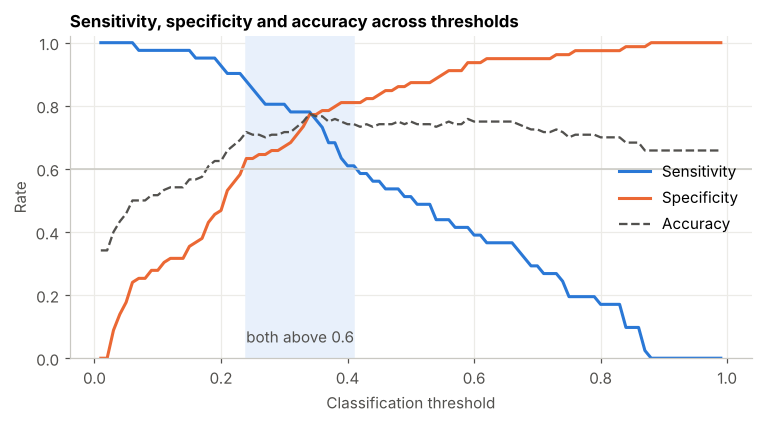

In [3]:
y = df.hydrochloric_acid
grid = np.round(np.arange(0.01, 1.00, 0.01), 2)
rows = []
for t in grid:
    pred = (p_hat >= t).astype(int)
    tp = ((pred == 1) & (y == 1)).sum(); tn = ((pred == 0) & (y == 0)).sum()
    rows.append({"threshold": t, "sensitivity": tp / y.sum(), "specificity": tn / (1 - y).sum(), "accuracy": (pred == y).mean()})
th = pd.DataFrame(rows)
valid = th[(th.sensitivity > 0.6) & (th.specificity > 0.6)]
best = th[th.accuracy == th.accuracy.max()]
baseline = max(y.mean(), 1 - y.mean())
print(f"Thresholds with sensitivity and specificity above 0.6: {valid.threshold.min():.2f} to {valid.threshold.max():.2f}")
print(f"Best accuracy {best.accuracy.iloc[0]:.3f} at threshold {best.threshold.min():.2f}"
      f"{'' if len(best) == 1 else f' to {best.threshold.max():.2f}'}; always guessing sulfuric gives {baseline:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.axvspan(valid.threshold.min(), valid.threshold.max(), color="#e8f0fb")
ax.plot(th.threshold, th.sensitivity, color=BLUE, lw=2, label="Sensitivity")
ax.plot(th.threshold, th.specificity, color=ORANGE, lw=2, label="Specificity")
ax.plot(th.threshold, th.accuracy, color=MUTED, lw=1.5, ls="--", label="Accuracy")
ax.axhline(0.6, color=GREY, lw=1)
ax.text(valid.threshold.mean(), 0.05, "both above 0.6", ha="center", color=MUTED)
ax.set(xlabel="Classification threshold", ylabel="Rate", ylim=(0, 1.02),
       title="Sensitivity, specificity and accuracy across thresholds")
ax.legend(frameon=False, loc="center right")
fig.savefig(FIG / "02_threshold_tradeoff.png"); plt.show()

**Reading.** Thresholds from 0.24 to 0.41 keep both sensitivity and specificity above 0.6. Accuracy peaks at 0.775 at a threshold of 0.34, where sensitivity is 0.78 and specificity 0.77. For context, always guessing sulfuric acid would already be right 65.8% of the time, so the model adds about 12 points over that baseline.

The best threshold is well below 0.5 because hydrochloric acid is the minority class: a lower threshold is needed to catch it.

## 2.3 Predicted probabilities and the log-odds ratio

In [4]:
cases = pd.DataFrame({"temp": [23.2, 24.2, 25.2], "lumps": [1, 1, 1]}, index=["A", "B", "C"])
cases["P(hydrochloric)"] = logit.predict(cases)
cases["log-odds"] = np.log(cases["P(hydrochloric)"] / (1 - cases["P(hydrochloric)"]))
display(cases.round(4))
print("B - A:", round(cases.loc["B", "log-odds"] - cases.loc["A", "log-odds"], 4),
      "| C - B:", round(cases.loc["C", "log-odds"] - cases.loc["B", "log-odds"], 4),
      "| temperature coefficient:", round(logit.params["temp"], 4))

,temp,lumps,P(hydrochloric),log-odds
A,23.2,1,0.2176,-1.2796
B,24.2,1,0.2022,-1.3727
C,25.2,1,0.1876,-1.4657


B - A: -0.0931 | C - B: -0.0931 | temperature coefficient: -0.0931


**Reading.** Each one-degree step changes the log-odds by exactly the temperature coefficient (−0.093), whatever the starting temperature. This is the defining property of logistic regression: effects are constant on the log-odds scale, even though the change in probability (from 21.8% to 20.2% to 18.8%) is not.

## Summary

| Question | Answer |
|---|---|
| Model | log-odds = 2.949 − 0.093·temp − 2.070·lumps; AUC 0.82 |
| Thresholds with sensitivity and specificity above 0.6 | 0.24 to 0.41 |
| Accuracy-maximising threshold | 0.34 (accuracy 0.775 vs 0.658 baseline) |
| P(hydrochloric) at 23.2°, 24.2°, 25.2° with lumps | 21.8%, 20.2%, 18.8% |